Device: cpu

Project Configuration
---------------------
Users : 3
Relays: 3
Total Power: 10.0

Starting training...



/tmp/ipykernel_1009/1637294848.py:472: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  states = torch.FloatTensor([


Episode 25/300 | Reward: 555.135
Episode 50/300 | Reward: 1304.507
Episode 75/300 | Reward: 1168.675
Episode 100/300 | Reward: 505.039
Episode 125/300 | Reward: 795.523
Episode 150/300 | Reward: 970.069
Episode 175/300 | Reward: 754.900
Episode 200/300 | Reward: 1187.177
Episode 225/300 | Reward: 1169.401
Episode 250/300 | Reward: 1535.362
Episode 275/300 | Reward: 532.856
Episode 300/300 | Reward: 555.710

Training completed.


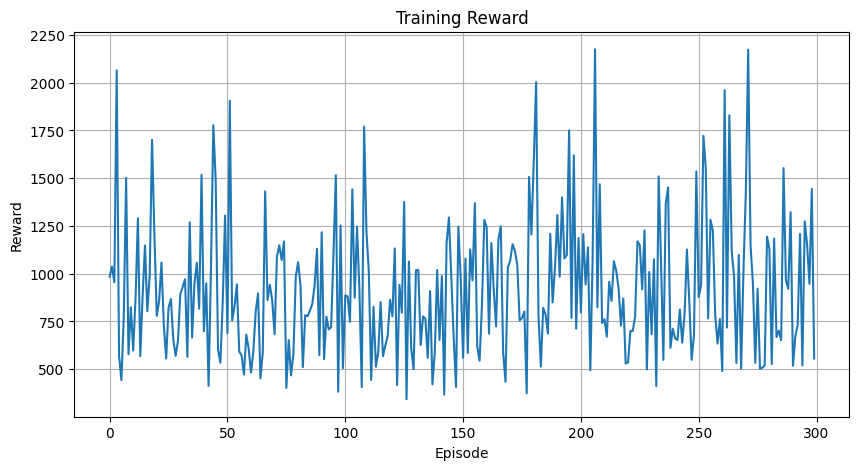


AI Results


,method,throughput,SINR,energy_efficiency,BER,outage,power
0,AI-Based,4.315079,20.731667,1.300537,3.345066e-07,0.0,10.0
1,AI-Based,3.412187,14.233371,1.231997,2.430364e-03,0.0,10.0
2,AI-Based,4.256013,19.340771,1.281261,3.180450e-07,0.0,10.0
3,AI-Based,3.472577,11.886575,1.064710,2.455101e-03,0.0,10.0
4,AI-Based,3.502802,16.512839,1.347286,4.465066e-02,0.0,10.0



Random Relay Results


,method,throughput,SINR,energy_efficiency,BER,outage,power
0,Random Relay,4.346907,22.531317,1.458003,0.000062,0.0,10.0
1,Random Relay,3.904629,15.103425,1.286004,0.000012,0.0,10.0
2,Random Relay,4.003321,45.661721,1.165243,0.052798,0.0,10.0
3,Random Relay,3.951252,20.113864,1.365462,0.005232,0.0,10.0
4,Random Relay,3.334557,13.062975,1.223441,0.028993,0.0,10.0



Fixed Relay Results


,method,throughput,SINR,energy_efficiency,BER,outage,power
0,Fixed Relay,3.496044,16.055195,1.024628,0.004954,0.0,10.0
1,Fixed Relay,3.566308,21.491994,1.028971,0.007820,0.0,10.0
2,Fixed Relay,3.699267,26.983726,1.060220,0.005122,0.0,10.0
3,Fixed Relay,3.694861,19.300384,1.080541,0.001264,0.0,10.0
4,Fixed Relay,3.521022,14.290596,1.035387,0.000953,0.0,10.0



Complete Results


,method,throughput,SINR,energy_efficiency,BER,outage,power
0,AI-Based,4.315079,20.731667,1.300537,3.345066e-07,0.000000,10.0
1,AI-Based,3.412187,14.233371,1.231997,2.430364e-03,0.000000,10.0
2,AI-Based,4.256013,19.340771,1.281261,3.180450e-07,0.000000,10.0
3,AI-Based,3.472577,11.886575,1.064710,2.455101e-03,0.000000,10.0
4,AI-Based,3.502802,16.512839,1.347286,4.465066e-02,0.000000,10.0
5,AI-Based,3.564407,13.339360,1.091374,4.460538e-03,0.000000,10.0
6,AI-Based,3.700562,16.129484,1.125315,6.177873e-03,0.000000,10.0
7,AI-Based,2.621333,12.634836,0.611784,1.652246e-01,0.333333,10.0
8,AI-Based,3.856798,14.693229,1.191551,1.462046e-04,0.000000,10.0
9,AI-Based,3.552002,13.027584,1.119399,4.563906e-03,0.000000,10.0



FINAL PERFORMANCE COMPARISON


,method,throughput,SINR,energy_efficiency,BER,outage,power
0,AI-Based,3.603811,28.271621,1.099440,0.044176,0.094667,10.0
1,Fixed Relay,3.627644,31.379250,1.109886,0.048191,0.102889,10.0
2,Random Relay,3.551497,26.139569,1.086480,0.045458,0.096889,10.0


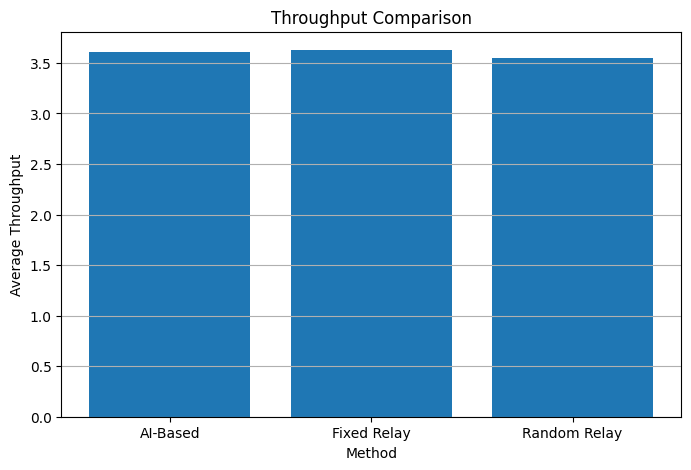

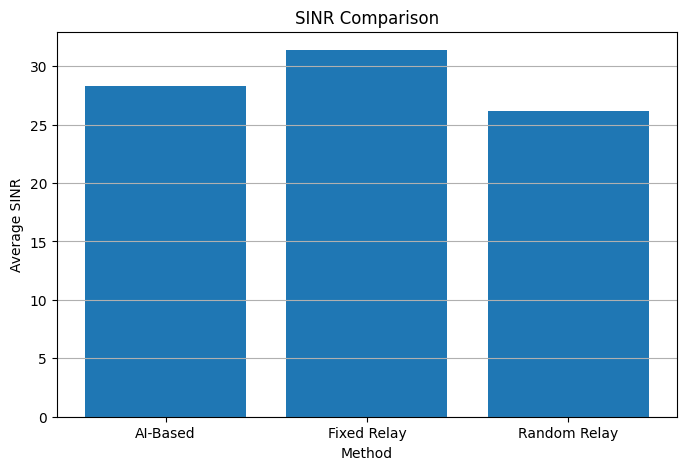

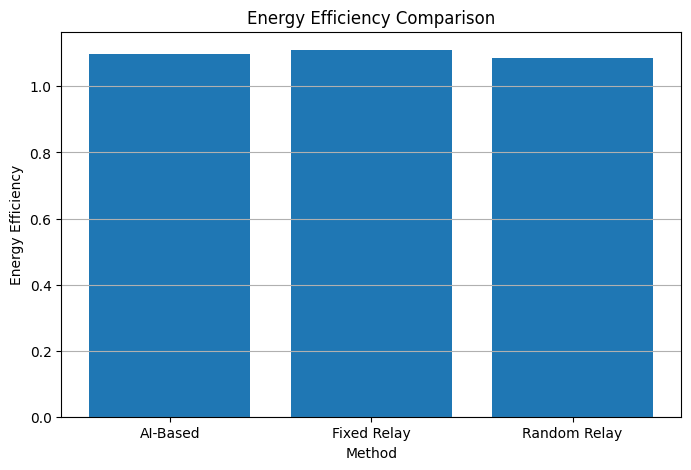

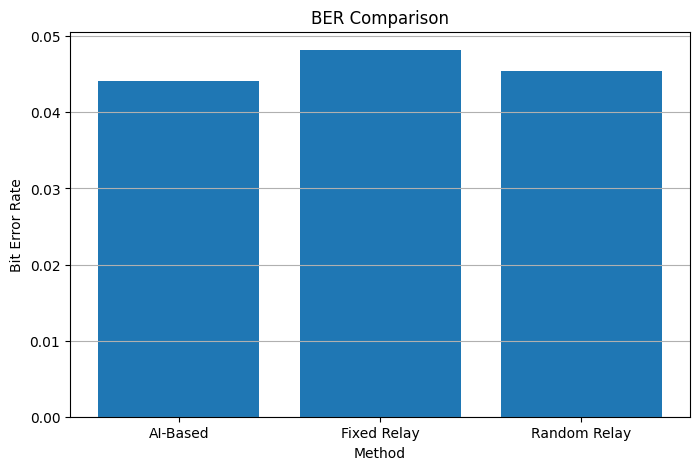

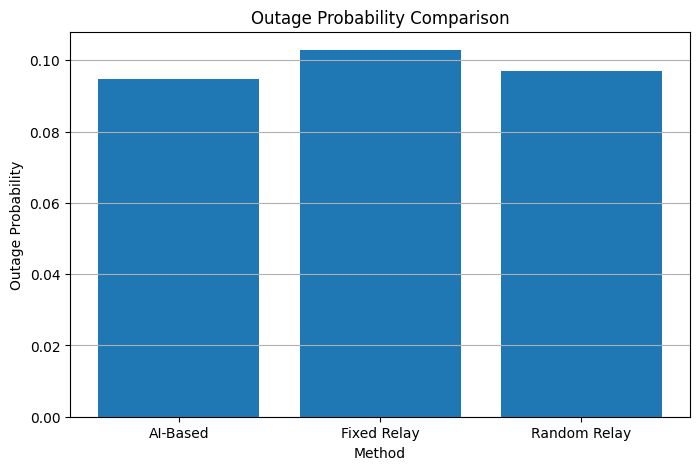

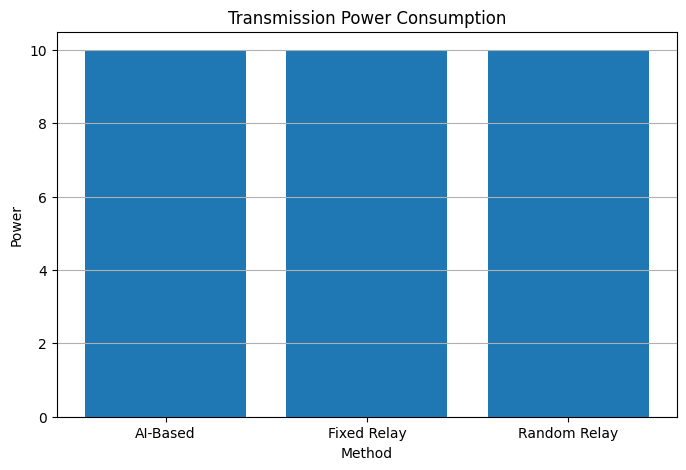


Files created:
1. NOMA_Relay_PPO_Results.csv
2. NOMA_All_Simulation_Results.csv

PROJECT SIMULATION COMPLETED

Application:
AI-Based Intelligent Relay Selection and
Power Allocation for Cooperative NOMA

Main AI Inputs:
- Channel Quality
- Interference
- User Requirements
- Relay Conditions
- Available Power

Main Decisions:
- Relay Selection
- Power Allocation

Performance Metrics:
- Throughput
- Data Rate
- SINR
- Energy Efficiency
- BER
- Outage Probability
- Transmission Power Consumption

Comparison:
- AI-Based Approach
- Random Relay Selection
- Fixed Relay Selection



In [1]:
!pip -q install gymnasium torch numpy pandas matplotlib scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym

from collections import deque

np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)



NUM_USERS = 3
NUM_RELAYS = 3

TOTAL_POWER = 10.0
NOISE_POWER = 0.01

NUM_EPISODES = 300
STEPS_PER_EPISODE = 30

LEARNING_RATE = 0.001
GAMMA = 0.99

print("\nProject Configuration")
print("---------------------")
print("Users :", NUM_USERS)
print("Relays:", NUM_RELAYS)
print("Total Power:", TOTAL_POWER)



class WirelessNetwork:

    def __init__(self,
                 num_users=NUM_USERS,
                 num_relays=NUM_RELAYS):

        self.num_users = num_users
        self.num_relays = num_relays

        self.channel_quality = None
        self.interference = None
        self.signal_strength = None
        self.user_requirements = None
        self.available_power = None

        self.reset()

    def reset(self):

        self.channel_quality = np.random.uniform(
            0.1, 1.0,
            size=(self.num_users, self.num_relays)
        )

        self.interference = np.random.uniform(
            0.01, 0.30,
            size=(self.num_users, self.num_relays)
        )

        self.signal_strength = np.random.uniform(
            0.2, 1.0,
            size=(self.num_users, self.num_relays)
        )

        self.user_requirements = np.random.uniform(
            0.2, 1.0,
            size=self.num_users
        )

        self.available_power = TOTAL_POWER

        return self.get_state()

    def get_state(self):

        return np.concatenate([
            self.channel_quality.flatten(),
            self.interference.flatten(),
            self.signal_strength.flatten(),
            self.user_requirements,
            [self.available_power / TOTAL_POWER]
        ])

    def step_network(self):

        self.channel_quality = np.clip(
            self.channel_quality +
            np.random.normal(0, 0.05, self.channel_quality.shape),
            0.01, 1.0
        )

        self.interference = np.clip(
            self.interference +
            np.random.normal(0, 0.02, self.interference.shape),
            0.001, 1.0
        )

        self.signal_strength = np.clip(
            self.signal_strength +
            np.random.normal(0, 0.05, self.signal_strength.shape),
            0.01, 1.0
        )

        return self.get_state()



def calculate_sinr(channel_quality,
                   power,
                   interference,
                   noise=NOISE_POWER):

    signal = channel_quality * power

    sinr = signal / (interference + noise)

    return max(sinr, 0.0)


def calculate_throughput(sinr):

    return np.log2(1 + sinr)


def calculate_energy_efficiency(throughput, power):

    if power <= 0:
        return 0
    return throughput / power


def calculate_ber(sinr):

    ber = 0.5 * np.exp(-sinr)

    return np.clip(ber, 0, 0.5)


def calculate_outage(sinr, threshold=1.0):

    return 1 if sinr < threshold else 0



def select_best_relay(network, user):

    scores = []

    for relay in range(network.num_relays):

        channel = network.channel_quality[user, relay]

        signal = network.signal_strength[user, relay]

        interference = network.interference[user, relay]

        score = channel + signal - interference

        scores.append(score)

    return int(np.argmax(scores))



def random_relay_selection(network, user):

    return np.random.randint(0, network.num_relays)


def fixed_relay_selection(network, user):

    return 0



def allocate_power(channel_quality,
                   total_power=TOTAL_POWER):

    channel_quality = np.maximum(channel_quality, 0.001)

    power = (
        channel_quality /
        np.sum(channel_quality)
    ) * total_power

    return power


def equal_power_allocation(num_users,
                           total_power=TOTAL_POWER):

    return np.ones(num_users) * (
        total_power / num_users
    )



class NOMAEnvironment:

    def __init__(self):

        self.network = WirelessNetwork()

        self.num_users = NUM_USERS
        self.num_relays = NUM_RELAYS

        self.state_size = len(
            self.network.get_state()
        )

        self.action_size = (
            self.num_users * self.num_relays
        )

    def reset(self):

        return self.network.reset()

    def step(self, actions):

        total_throughput = 0
        total_energy_efficiency = 0
        total_ber = 0
        total_outage = 0
        total_sinr = 0

        selected_channels = []

        for user in range(self.num_users):

            relay = actions[user]

            channel = self.network.channel_quality[
                user, relay
            ]

            selected_channels.append(channel)

        selected_channels = np.array(
            selected_channels
        )

        powers = allocate_power(
            selected_channels
        )

        results = []

        for user in range(self.num_users):

            relay = actions[user]

            channel = self.network.channel_quality[
                user, relay
            ]

            interference = self.network.interference[
                user, relay
            ]

            power = powers[user]

            sinr = calculate_sinr(
                channel,
                power,
                interference
            )

            throughput = calculate_throughput(
                sinr
            )

            efficiency = calculate_energy_efficiency(
                throughput,
                power
            )

            ber = calculate_ber(sinr)

            outage = calculate_outage(sinr)

            total_sinr += sinr
            total_throughput += throughput
            total_energy_efficiency += efficiency
            total_ber += ber
            total_outage += outage

            results.append({
                "user": user + 1,
                "relay": relay + 1,
                "power": power,
                "SINR": sinr,
                "throughput": throughput,
                "energy_efficiency": efficiency,"BER": ber,
                "outage": outage
            })

        avg_sinr = total_sinr / self.num_users
        avg_throughput = (
            total_throughput / self.num_users
        )
        avg_efficiency = (
            total_energy_efficiency / self.num_users
        )
        avg_ber = total_ber / self.num_users
        outage_probability = (
            total_outage / self.num_users
        )

        reward = (
            avg_throughput
            + avg_sinr
            + avg_efficiency
            - avg_ber
            - outage_probability
        )

        next_state = self.network.step_network()

        metrics = {
            "throughput": avg_throughput,
            "sinr": avg_sinr,
            "energy_efficiency": avg_efficiency,
            "ber": avg_ber,
            "outage": outage_probability,
            "power": np.sum(powers),
            "details": results
        }

        return (
            next_state,
            reward,
            metrics
        )



class Actor(nn.Module):

    def __init__(self,
                 state_size,
                 action_size):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(state_size, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, action_size)
        )

    def forward(self, state):

        return self.network(state)



class Critic(nn.Module):

    def __init__(self, state_size):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(state_size, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, 1)
        )

    def forward(self, state):

        return self.network(state)



class MultiAgentPPO:

    def __init__(self,
                 state_size,
                 action_size):

        self.actor = Actor(
            state_size,
            action_size
        ).to(device)

        self.critic = Critic(
            state_size
        ).to(device)

        self.actor_optimizer = optim.Adam(
            self.actor.parameters(),
            lr=LEARNING_RATE
        )

        self.critic_optimizer = optim.Adam(
            self.critic.parameters(),
            lr=LEARNING_RATE
        )

        self.gamma = GAMMA

        self.memory = []

    def select_action(self, state):

        state_tensor = torch.FloatTensor(
            state
        ).unsqueeze(0).to(device)

        logits = self.actor(
            state_tensor
        )

        probabilities = torch.softmax(
            logits,
            dim=-1
        )

        distribution = torch.distributions.Categorical(
            probabilities
        )

        action = distribution.sample()

        log_probability = distribution.log_prob(
            action
        )

        return (
            action.item(),
            log_probability.item()
        )

    def store(self,
              state,
              action,
              reward,
              log_probability):

        self.memory.append({
            "state": state,
            "action": action,
            "reward": reward,
            "log_probability": log_probability
        })

    def update(self):

        if len(self.memory) == 0:
            return

        states = torch.FloatTensor([
            x["state"] for x in self.memory
        ]).to(device)

        rewards = [
            x["reward"]
            for x in self.memory
        ]

        old_log_probs = torch.FloatTensor([x["log_probability"]
            for x in self.memory
        ]).to(device)

        returns = []

        discounted = 0

        for reward in reversed(rewards):

            discounted = (
                reward +
                self.gamma * discounted
            )

            returns.insert(
                0,
                discounted
            )

        returns = torch.FloatTensor(
            returns
        ).to(device)

        returns = (
            returns - returns.mean()
        ) / (
            returns.std() + 1e-8
        )

        values = self.critic(
            states
        ).squeeze()

        advantages = returns - values.detach()


        logits = self.actor(states)

        probabilities = torch.softmax(
            logits,
            dim=-1
        )

        actions = torch.LongTensor([
            x["action"]
            for x in self.memory
        ]).to(device)

        distribution = torch.distributions.Categorical(
            probabilities
        )

        new_log_probs = distribution.log_prob(
            actions
        )

        ratio = torch.exp(
            new_log_probs - old_log_probs
        )

        epsilon = 0.2

        clipped_ratio = torch.clamp(
            ratio,
            1 - epsilon,
            1 + epsilon
        )

        actor_loss = -torch.min(
            ratio * advantages,
            clipped_ratio * advantages
        ).mean()

        self.actor_optimizer.zero_grad()

        actor_loss.backward()

        self.actor_optimizer.step()


        critic_loss = (
            returns - values
        ).pow(2).mean()

        self.critic_optimizer.zero_grad()

        critic_loss.backward()

        self.critic_optimizer.step()

        self.memory.clear()



environment = NOMAEnvironment()

agent = MultiAgentPPO(
    environment.state_size,
    environment.action_size
)

training_rewards = []

print("\nStarting training...\n")

for episode in range(NUM_EPISODES):

    state = environment.reset()

    episode_reward = 0

    for step in range(STEPS_PER_EPISODE):

        actions = []
        log_probs = []

        for user in range(NUM_USERS):

            action, log_probability = (
                agent.select_action(state)
            )

            relay = action % NUM_RELAYS

            actions.append(relay)
            log_probs.append(log_probability)

        next_state, reward, metrics = (
            environment.step(actions)
        )

        agent.store(
            state,
            actions[0],
            reward,
            np.mean(log_probs)
        )

        state = next_state

        episode_reward += reward

    agent.update()

    training_rewards.append(
        episode_reward
    )

    if (episode + 1) % 25 == 0:

        print(
            f"Episode {episode + 1}/{NUM_EPISODES} "
            f"| Reward: {episode_reward:.3f}"
        )


print("\nTraining completed.")



plt.figure(figsize=(10, 5))

plt.plot(
    training_rewards
)

plt.title(
    "Training Reward"
)

plt.xlabel(
    "Episode"
)

plt.ylabel(
    "Reward"
)

plt.grid()

plt.show()



def evaluate_ai(environment,
                agent,
                episodes=50):

    results = []

    for episode in range(episodes):

        state = environment.reset()

        for step in range(STEPS_PER_EPISODE):

            actions = []

            for user in range(NUM_USERS):

                action, _ = agent.select_action(
                    state
                )

                relay = action % NUM_RELAYS

                actions.append(relay)

            next_state, reward, metrics = (
                environment.step(actions)
            )

            results.append({
                "method": "AI-Based",
                "throughput": metrics["throughput"],
                "SINR": metrics["sinr"],
                "energy_efficiency":
                    metrics["energy_efficiency"],
                "BER": metrics["ber"],
                "outage": metrics["outage"],
                "power": metrics["power"]
            })

            state = next_state

    return pd.DataFrame(results)


ai_results = evaluate_ai(
    environment,
    agent
)

print("\nAI Results")
display(
    ai_results.head()
)



def evaluate_random(episodes=50):

    results = []

    for episode in range(episodes):

        network = WirelessNetwork()

        for step in range(STEPS_PER_EPISODE):

            actions = []

            for user in range(NUM_USERS):

                relay = random_relay_selection(
                    network,
                    user
                )

                actions.append(relay)

            selected_channels = np.array([
                network.channel_quality[
                    user,
                    actions[user]
                ]
                for user in range(NUM_USERS)
            ])

            powers = allocate_power(
                selected_channels
            )

            throughput_values = []
            sinr_values = []
            efficiency_values = []
            ber_values = []
            outage_values = []

            for user in range(NUM_USERS):

                relay = actions[user]

                channel = network.channel_quality[
                    user,
                    relay
                ]

                interference = network.interference[
                    user,
                    relay
                ]

                sinr = calculate_sinr(
                    channel,
                    powers[user],
                    interference
                )

                throughput = calculate_throughput(
                    sinr
                )

                efficiency = (
                    calculate_energy_efficiency(
                        throughput,
                        powers[user]
                    )
                )

                ber = calculate_ber(sinr)

                outage = calculate_outage(
                    sinr
                )

                throughput_values.append(
                    throughput
                )

                sinr_values.append(
                    sinr
                )

                efficiency_values.append(
                    efficiency
                )

                ber_values.append(
                    ber
                )

                outage_values.append(
                    outage
                )

            results.append({
                "method": "Random Relay",
                "throughput":
                    np.mean(throughput_values),
                "SINR":
                    np.mean(sinr_values),
                "energy_efficiency":
                    np.mean(efficiency_values),
                "BER":
                    np.mean(ber_values),
                "outage":
                    np.mean(outage_values),
                "power":
                    np.sum(powers)
            })

            network.step_network()

    return pd.DataFrame(results)


random_results = evaluate_random()

print("\nRandom Relay Results")
display(
    random_results.head()
)



def evaluate_fixed(episodes=50):

    results = []

    for episode in range(episodes):

        network = WirelessNetwork()

        for step in range(STEPS_PER_EPISODE):

            actions = [
                fixed_relay_selection(
                    network,
                    user
                )
                for user in range(NUM_USERS)
            ]

            selected_channels = np.array([
                network.channel_quality[
                    user,
                    actions[user]
                ]
                for user in range(NUM_USERS)
            ])

            powers = allocate_power(
                selected_channels
            )

            throughput_values = []
            sinr_values = []
            efficiency_values = []
            ber_values = []
            outage_values = []

            for user in range(NUM_USERS):

                relay = actions[user]

                channel = network.channel_quality[
                    user,
                    relay
                ]

                interference = network.interference[
                    user,
                    relay
                ]

                sinr = calculate_sinr(
                    channel,
                    powers[user],
                    interference
                )

                throughput = calculate_throughput(
                    sinr
                )

                efficiency = (
                    calculate_energy_efficiency(
                        throughput,
                        powers[user]
                    )
                )

                ber = calculate_ber(sinr)

                outage = calculate_outage(
                    sinr
                )

                throughput_values.append(
                    throughput
                )

                sinr_values.append(
                    sinr
                )

                efficiency_values.append(
                    efficiency
                )

                ber_values.append(
                    ber
                )

                outage_values.append(
                    outage
                )

            results.append({
                "method": "Fixed Relay",
                "throughput":
                    np.mean(throughput_values),
                "SINR":
                    np.mean(sinr_values),
                "energy_efficiency":
                    np.mean(efficiency_values),
                "BER":
                    np.mean(ber_values),
                "outage":
                    np.mean(outage_values),
                "power":
                    np.sum(powers)
            })

            network.step_network()

    return pd.DataFrame(results)


fixed_results = evaluate_fixed()

print("\nFixed Relay Results")
display(
    fixed_results.head()
)



all_results = pd.concat(
    [
        ai_results,
        random_results,
        fixed_results
    ],
    ignore_index=True
)

print("\nComplete Results")
display(
    all_results.head(10)
)



summary = all_results.groupby(
    "method"
).agg({

    "throughput": "mean",

    "SINR": "mean",

    "energy_efficiency": "mean",

    "BER": "mean",

    "outage": "mean",

    "power": "mean"

}).reset_index()

print("\n==============================")
print("FINAL PERFORMANCE COMPARISON")
print("==============================")

display(summary)



plt.figure(figsize=(8, 5))

plt.bar(
    summary["method"],
    summary["throughput"]
)

plt.title(
    "Throughput Comparison"
)

plt.ylabel(
    "Average Throughput"
)

plt.xlabel(
    "Method"
)

plt.grid(axis="y")

plt.show()



plt.figure(figsize=(8, 5))

plt.bar(
    summary["method"],
    summary["SINR"]
)

plt.title(
    "SINR Comparison"
)

plt.ylabel(
    "Average SINR"
)

plt.xlabel(
    "Method"
)

plt.grid(axis="y")

plt.show()



plt.figure(figsize=(8, 5))

plt.bar(
    summary["method"],
    summary["energy_efficiency"]
)

plt.title(
    "Energy Efficiency Comparison"
)

plt.ylabel(
    "Energy Efficiency"
)

plt.xlabel(
    "Method"
)

plt.grid(axis="y")

plt.show()



plt.figure(figsize=(8, 5))

plt.bar(
    summary["method"],
    summary["BER"]
)

plt.title(
    "BER Comparison"
)

plt.ylabel(
    "Bit Error Rate"
)

plt.xlabel(
    "Method"
)

plt.grid(axis="y")

plt.show()



plt.figure(figsize=(8, 5))

plt.bar(
    summary["method"],
    summary["outage"]
)

plt.title(
    "Outage Probability Comparison"
)

plt.ylabel(
    "Outage Probability"
)

plt.xlabel(
    "Method"
)

plt.grid(axis="y")

plt.show()



plt.figure(figsize=(8, 5))

plt.bar(
    summary["method"],
    summary["power"]
)

plt.title(
    "Transmission Power Consumption"
)

plt.ylabel(
    "Power"
)

plt.xlabel(
    "Method"
)

plt.grid(axis="y")

plt.show()



summary.to_csv(
    "NOMA_Relay_PPO_Results.csv",
    index=False
)

all_results.to_csv(
    "NOMA_All_Simulation_Results.csv",
    index=False
)

print("\nFiles created:")
print("1. NOMA_Relay_PPO_Results.csv")
print("2. NOMA_All_Simulation_Results.csv")



print("\n==============================================")
print("PROJECT SIMULATION COMPLETED")
print("==============================================")

print("""
Application:
AI-Based Intelligent Relay Selection and
Power Allocation for Cooperative NOMA

Main AI Inputs:
- Channel Quality
- Interference
- User Requirements
- Relay Conditions
- Available Power

Main Decisions:
- Relay Selection
- Power Allocation

Performance Metrics:
- Throughput
- Data Rate
- SINR
- Energy Efficiency
- BER
- Outage Probability
- Transmission Power Consumption

Comparison:
- AI-Based Approach
- Random Relay Selection
- Fixed Relay Selection
""")
